## testing

In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import numpy as np
import os
import xarray as xr
import xcdat as xc
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm as BM
import pandas as pd
import matplotlib as mpl
import matplotlib.ticker as mticker
import netCDF4
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.util import add_cyclic_point
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER

In [3]:
from scipy import stats

In [4]:
mpl.rcParams['font.family'] = 'Droid Sans'
mpl.rcParams['font.size'] = 12
# Edit axes parameters
mpl.rcParams['axes.linewidth'] = 2.0
# Tick properties
mpl.rcParams['xtick.major.size'] = 5
mpl.rcParams['xtick.minor.size'] = 3
mpl.rcParams['xtick.major.width'] = 1
mpl.rcParams['xtick.direction'] = 'out'
mpl.rcParams['ytick.major.size'] = 5
mpl.rcParams['ytick.minor.size'] = 3
mpl.rcParams['ytick.major.width'] = 1
mpl.rcParams['ytick.direction'] = 'out'

In [5]:
# plt.style.use('dark_background')

### Functions needed for the analysis

In [9]:
import matplotlib as m
from matplotlib.colors import BoundaryNorm as BM
import matplotlib.patches as mpatches

def plot_background(ax):
    ax.add_feature(cfeature.COASTLINE, alpha=0.9, lw=1.1)
    ax.set_global()
    # ax.add_feature(cfeature.LAND, color='lightgray')
    # ax.add_feature(cfeature.OCEAN, color='lightgray')
    gl = ax.gridlines(draw_labels=True,
                      linewidth=1, color='gray', alpha=0.01, linestyle='--')
    gl.top_labels = False
    # gl.left_labels = False
    # gl.bottom_labels = False
    gl.right_labels = False
    gl.xlines = False
    # gl.xlocator = mticker.FixedLocator([-180, -45, 0, 45, 180])
    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER
    gl.xlabel_style = {'size': 10, 'color': 'k'}
    gl.ylabel_style = {'size': 10, 'color': 'k'}
    return ax


def plot_maps(x, y, z, titles, labels, cmap, levels, cbar_label = 'Precip', pval = [], nrows=1, ncols=3, figsize=(12,4), land_mask_list = [0], add_patch=False):
    fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize, constrained_layout=True, subplot_kw={'projection':ccrs.Robinson(central_longitude=180)})
    
    axlist = axarr.flatten()
    
    for ax in axlist:
        plot_background(ax)
    
    for i in range(len(z)):
        axlist[i].contourf(x, y, z[i], cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
        axlist[i].set_title(titles[i])
        if i in land_mask_list:
            axlist[i].add_feature(cfeature.LAND, color = 'k', zorder=1)
        if pval != []:
            pval_plot = np.ma.masked_less_equal(pval[i], 0.05)
            axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='////', transform = ccrs.PlateCarree(central_longitude=0))
        axlist[i].set_title(titles[i], fontdict={'fontsize':12})
        axlist[i].text(0.1, 1.05, labels[i], size=16, fontweight='bold', transform=axlist[i].transAxes)
        if add_patch:
            axlist[i].add_patch(mpatches.Rectangle(xy=[120, -65], width=170, height=20,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[250, -30], width=40, height=20,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
        
    norm = BM(levels, 256, extend='both')
    fig.colorbar(m.cm.ScalarMappable(norm = norm, cmap=cmap), ax = axlist, \
                orientation = 'horizontal', shrink=0.4, aspect = 20, pad = 0.05, label = cbar_label)

In [10]:
from functions import preproc_funcs as funcs

In [11]:
from functions import xr_lowess

In [15]:
out_cmip = xr.open_dataset('/g/data/ob22/as8561/data/enso_precip_asymmetry_result/out_conc.nc')
out_access = xr.open_dataset('/g/data/ob22/as8561/data/enso_precip_asymmetry_result/out_access_le.nc')
out_canesm = xr.open_dataset('/g/data/ob22/as8561/data/enso_precip_asymmetry_result/out_canesm5_le.nc')
out_miroc  = xr.open_dataset('/g/data/ob22/as8561/data/enso_precip_asymmetry_result/out_miroc6_le.nc')

In [16]:
import seaborn as sns

In [17]:
out_cmip['enc'] = out_cmip.nino - out_cmip.neut
out_cmip['lnc'] = out_cmip.nina - out_cmip.neut

In [18]:
out_access['enc'] = out_access.nino - out_access.neut
out_access['lnc'] = out_access.nina - out_access.neut

In [19]:
out_canesm['enc'] = out_canesm.nino - out_canesm.neut
out_canesm['lnc'] = out_canesm.nina - out_canesm.neut

In [20]:
out_miroc['enc'] = out_miroc.nino - out_miroc.neut
out_miroc['lnc'] = out_miroc.nina - out_miroc.neut

(-3.0, 3.0)

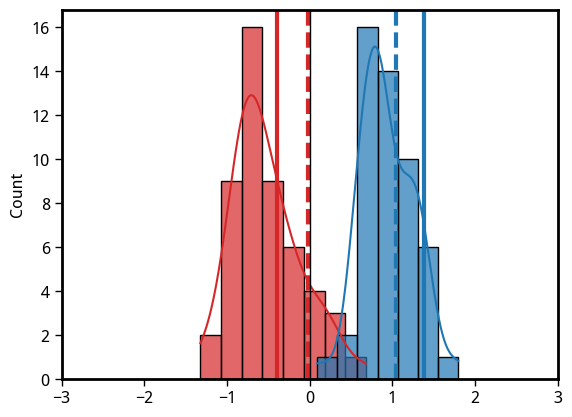

In [40]:
sns.histplot(out_cmip.enc.isel(season=0, region=41, model=slice(0,-2)), color='tab:red', lw=1.0, kde=True, alpha=0.7)
plt.axvline(out_cmip.enc.isel(season=0, region=41, model=-2), color='tab:red', lw=3.0)
plt.axvline(out_cmip.enc.isel(season=0, region=41, model=-1), color='tab:red', lw=3.0, ls='--')

sns.histplot(out_cmip.lnc.isel(season=0, region=41, model=slice(0,-2)), color='tab:blue', lw=1.0, kde=True, alpha=0.7)
plt.axvline(out_cmip.lnc.isel(season=0, region=41, model=-2), color='tab:blue', lw=3.0)
plt.axvline(out_cmip.lnc.isel(season=0, region=41, model=-1), color='tab:blue', lw=3.0, ls='--')

plt.axvline(0.0, color='k', lw=1.0, ls='-')
plt.xlim(-3, 3)

(-1.0, 0.2)

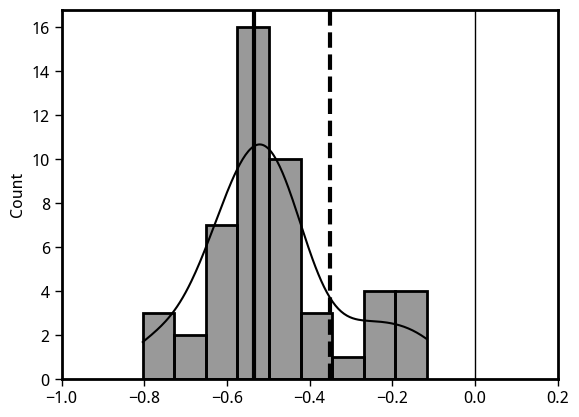

In [41]:
sns.histplot(out_cmip.corr_coef.isel(season=0, region=41, model=slice(0,-2)), color='k', lw=2.0, kde=True, alpha=0.4)
plt.axvline(out_cmip.corr_coef.isel(season=0, region=41, model=-2), color='k', lw=3.0)
plt.axvline(out_cmip.corr_coef.isel(season=0, region=41, model=-1), color='k', lw=3.0, ls='--')

plt.axvline(0.0, color='k', lw=1.0, ls='-')
plt.xlim(-1, 0.2)

(-3.0, 3.0)

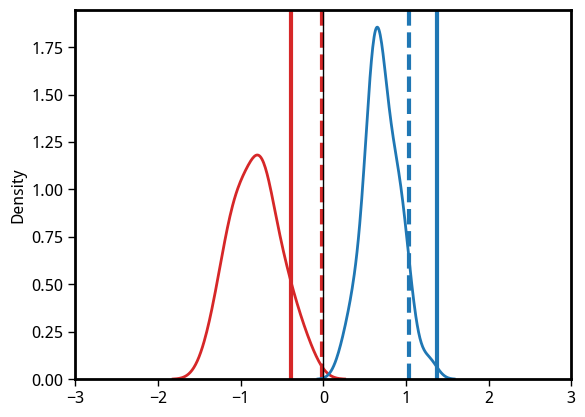

In [23]:
sns.kdeplot(out_access.enc.isel(season=0, region=41), color='tab:red', lw=2.0)
plt.axvline(out_cmip.enc.isel(season=0, region=41, model=-2), color='tab:red', lw=3.0)
plt.axvline(out_cmip.enc.isel(season=0, region=41, model=-1), color='tab:red', lw=3.0, ls='--')

sns.kdeplot(out_access.lnc.isel(season=0, region=41), color='tab:blue', lw=2.0)
plt.axvline(out_cmip.lnc.isel(season=0, region=41, model=-2), color='tab:blue', lw=3.0)
plt.axvline(out_cmip.lnc.isel(season=0, region=41, model=-1), color='tab:blue', lw=3.0, ls='--')

plt.axvline(0.0, color='k', lw=1.0, ls='-')
plt.xlim(-3, 3)

(-1.0, 0.2)

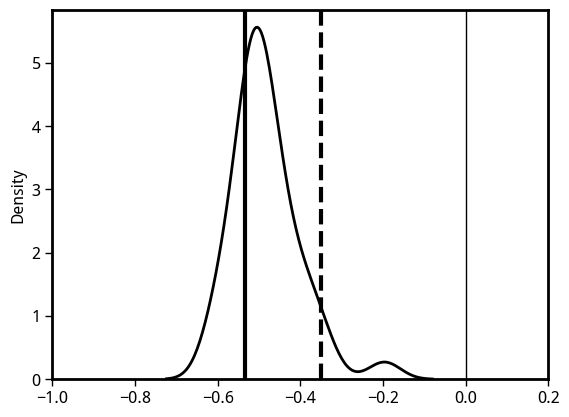

In [24]:
sns.kdeplot(out_access.corr_coef.isel(season=0, region=41, model=slice(0,-2)), color='k', lw=2.0)
plt.axvline(out_cmip.corr_coef.isel(season=0, region=41, model=-2), color='k', lw=3.0)
plt.axvline(out_cmip.corr_coef.isel(season=0, region=41, model=-1), color='k', lw=3.0, ls='--')

plt.axvline(0.0, color='k', lw=1.0, ls='-')
plt.xlim(-1, 0.2)

(-3.0, 3.0)

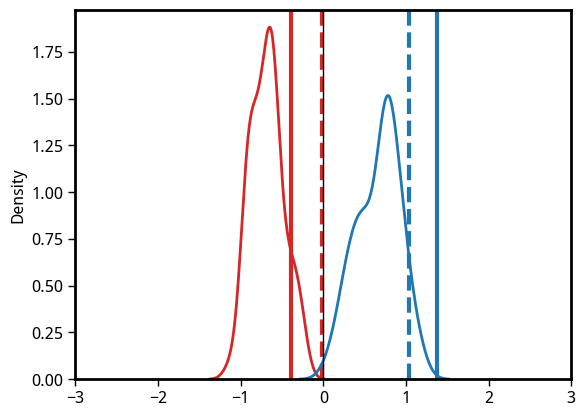

In [25]:
sns.kdeplot(out_canesm.enc.isel(season=0, region=41), color='tab:red', lw=2.0)
plt.axvline(out_cmip.enc.isel(season=0, region=41, model=-2), color='tab:red', lw=3.0)
plt.axvline(out_cmip.enc.isel(season=0, region=41, model=-1), color='tab:red', lw=3.0, ls='--')

sns.kdeplot(out_canesm.lnc.isel(season=0, region=41), color='tab:blue', lw=2.0)
plt.axvline(out_cmip.lnc.isel(season=0, region=41, model=-2), color='tab:blue', lw=3.0)
plt.axvline(out_cmip.lnc.isel(season=0, region=41, model=-1), color='tab:blue', lw=3.0, ls='--')

plt.axvline(0.0, color='k', lw=1.0, ls='-')
plt.xlim(-3, 3)

(-1.0, 0.2)

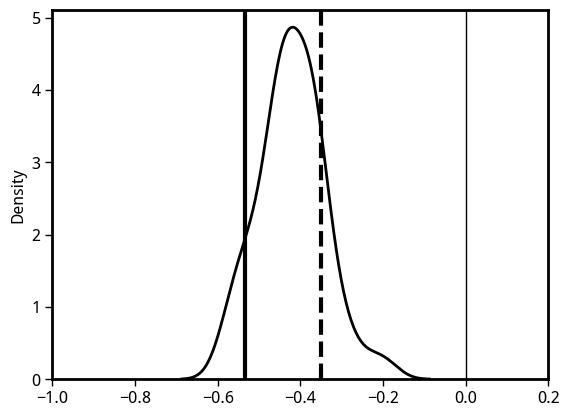

In [26]:
sns.kdeplot(out_canesm.corr_coef.isel(season=0, region=41, model=slice(0,-2)), color='k', lw=2.0)
plt.axvline(out_cmip.corr_coef.isel(season=0, region=41, model=-2), color='k', lw=3.0)
plt.axvline(out_cmip.corr_coef.isel(season=0, region=41, model=-1), color='k', lw=3.0, ls='--')

plt.axvline(0.0, color='k', lw=1.0, ls='-')
plt.xlim(-1, 0.2)

(-3.0, 3.0)

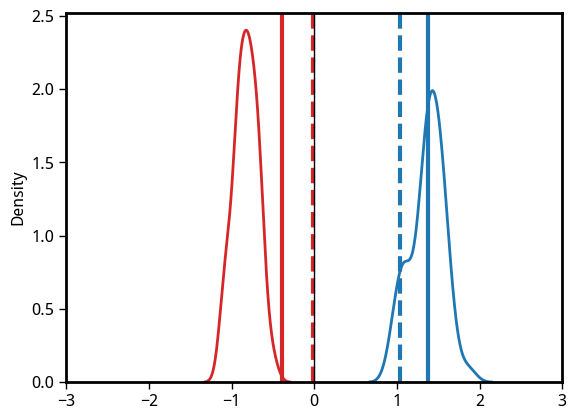

In [27]:
sns.kdeplot(out_miroc.enc.isel(season=0, region=41), color='tab:red', lw=2.0)
plt.axvline(out_cmip.enc.isel(season=0, region=41, model=-2), color='tab:red', lw=3.0)
plt.axvline(out_cmip.enc.isel(season=0, region=41, model=-1), color='tab:red', lw=3.0, ls='--')

sns.kdeplot(out_miroc.lnc.isel(season=0, region=41), color='tab:blue', lw=2.0)
plt.axvline(out_cmip.lnc.isel(season=0, region=41, model=-2), color='tab:blue', lw=3.0)
plt.axvline(out_cmip.lnc.isel(season=0, region=41, model=-1), color='tab:blue', lw=3.0, ls='--')

plt.axvline(0.0, color='k', lw=1.0, ls='-')
plt.xlim(-3, 3)

(-1.0, 0.2)

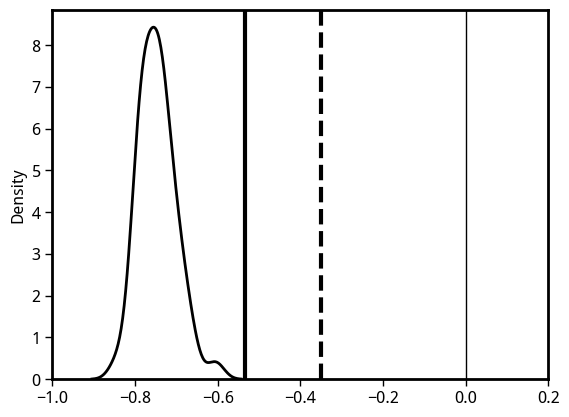

In [28]:
sns.kdeplot(out_miroc.corr_coef.isel(season=0, region=41, model=slice(0,-2)), color='k', lw=2.0)
plt.axvline(out_cmip.corr_coef.isel(season=0, region=41, model=-2), color='k', lw=3.0)
plt.axvline(out_cmip.corr_coef.isel(season=0, region=41, model=-1), color='k', lw=3.0, ls='--')

plt.axvline(0.0, color='k', lw=1.0, ls='-')
plt.xlim(-1, 0.2)

In [29]:
ts5 = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/CMIP6_models/ts_ssp5.nc')
ts5_ext = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/CMIP6_models/ts_ssp5_ext.nc')

psl5 = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/CMIP6_models/psl_ssp5.nc')
psl5_ext = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/CMIP6_models/psl_ssp5_ext.nc')

In [30]:
# out5o = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/out_ssp5_over.nc')
# out5o_ext = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/out_ssp5_over_extensions.nc')

# psl5o = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/psl_ssp5_over.nc')
# psl5o_ext = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/psl_ssp5_over_extensions.nc')

In [31]:
ts3 = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/CMIP6_models/ts_ssp3.nc')
psl3 = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/CMIP6_models/psl_ssp3.nc')

In [32]:
ts2 = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/CMIP6_models/ts_ssp2.nc')
psl2 = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/CMIP6_models/psl_ssp2.nc')

In [33]:
ts1 = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/CMIP6_models/ts_ssp1.nc')
ts1_ext = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/CMIP6_models/ts_ssp1_ext.nc')
psl1 = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/CMIP6_models/psl_ssp1.nc')
psl1_ext = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/CMIP6_models/psl_ssp1_ext.nc')

In [34]:
# ts5o = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/CMIP6_models/ts_ssp5o.nc')
ts5o_ext = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/CMIP6_models/ts_ssp5o_ext.nc')
# psl5o = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/CMIP6_models/psl_ssp5o.nc')
psl5o_ext = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/CMIP6_models/psl_ssp5o_ext.nc')

In [35]:
xx, yy = np.meshgrid(ts5.lon, ts5.lat)

In [36]:
weights = np.cos(np.deg2rad(ts5.lat))
weights.name='weights'
weights

<xarray.DataArray 'weights' (lat: 120)>
array([0.0130896 , 0.03925982, 0.06540313, 0.09150162, 0.1175374 ,
       0.14349262, 0.1693495 , 0.19509032, 0.22069744, 0.24615329,
       0.27144045, 0.29654157, 0.32143947, 0.34611706, 0.37055744,
       0.39474386, 0.41865974, 0.44228869, 0.46561452, 0.48862124,
       0.51129309, 0.53361452, 0.55557023, 0.57714519, 0.5983246 ,
       0.61909395, 0.639439  , 0.65934582, 0.67880075, 0.69779046,
       0.71630194, 0.73432251, 0.75183981, 0.76884183, 0.78531693,
       0.80125381, 0.81664156, 0.83146961, 0.84572782, 0.85940641,
       0.87249601, 0.88498764, 0.89687274, 0.90814317, 0.91879121,
       0.92880955, 0.93819134, 0.94693013, 0.95501994, 0.96245524,
       0.96923091, 0.97534232, 0.98078528, 0.98555606, 0.98965139,
       0.99306846, 0.99580493, 0.99785892, 0.99922904, 0.99991433,
       0.99991433, 0.99922904, 0.99785892, 0.99580493, 0.99306846,
       0.98965139, 0.98555606, 0.98078528, 0.97534232, 0.96923091,
       0.96245524, 0.95501994, 0.94693013, 0.93819134, 0.92880955,
       0.91879121, 0.90814317, 0.89687274, 0.88498764, 0.87249601,
       0.85940641, 0.84572782, 0.83146961, 0.81664156, 0.80125381,
       0.78531693, 0.76884183, 0.75183981, 0.73432251, 0.71630194,
       0.69779046, 0.67880075, 0.65934582, 0.639439  , 0.61909395,
       0.5983246 , 0.57714519, 0.55557023, 0.53361452, 0.51129309,
       0.48862124, 0.46561452, 0.44228869, 0.41865974, 0.39474386,
       0.37055744, 0.34611706, 0.32143947, 0.29654157, 0.27144045,
       0.24615329, 0.22069744, 0.19509032, 0.1693495 , 0.14349262,
       0.1175374 , 0.09150162, 0.06540313, 0.03925982, 0.0130896 ])
Coordinates:
  * lat      (lat) float64 -89.25 -87.75 -86.25 -84.75 ... 86.25 87.75 89.25
Attributes:
    standard_name:  latitude
    long_name:      latitude
    units:          degrees_north
    axis:           Y

In [37]:
nino34_ssp5 = ts5.ts.sel(lat = slice(-5,5), lon = slice(-170+360, -120+360)).weighted(weights).mean(('lat', 'lon'))
nino34_ssp3 = ts3.ts.sel(lat = slice(-5,5), lon = slice(-170+360, -120+360)).weighted(weights).mean(('lat', 'lon'))
nino34_ssp2 = ts2.ts.sel(lat = slice(-5,5), lon = slice(-170+360, -120+360)).weighted(weights).mean(('lat', 'lon'))
nino34_ssp1 = ts1.ts.sel(lat = slice(-5,5), lon = slice(-170+360, -120+360)).weighted(weights).mean(('lat', 'lon'))
# nino34_ssp5o = ts5o.ts.sel(lat = slice(-5,5), lon = slice(-170+360, -120+360)).weighted(weights).mean(('lat', 'lon'))

In [42]:
nino34_ssp5.isel(time = slice(0,30))

<xarray.DataArray 'ts' (model: 47, time: 250)>
array([[-1.18643051, -0.44232259, -0.284698  , ...,  5.54220158,
         4.98909404,  5.96241855],
       [-1.18643051, -0.44232259, -0.284698  , ...,  5.54220158,
         4.98909404,  5.96241855],
       [-0.58242597,  0.95274776, -0.26042353, ...,  7.10680545,
         8.11239849,  6.21508738],
       ...,
       [ 1.19047053, -2.33572312, -1.84463004, ...,  3.50353165,
         5.40920404,  3.56901744],
       [-0.94601824, -0.12330277, -0.20603272, ...,  4.10704738,
         5.46954663,  2.96375851],
       [-1.17707334,  0.39418266, -0.80095032, ...,  3.4065668 ,
         3.83589284,  3.8746316 ]])
Coordinates:
  * time     (time) datetime64[ns] 1850-06-01 1851-06-01 ... 2099-06-01
  * model    (model) object 'CanESM5' 'CanESM5-CanOE' ... 'BCC-CSM2-MR'